# Temperature or Energy? Building melting physics into graph neural networks for melt-pool simulation

CS4350 group project: Giorgio Bernardini, Luc Dop, Jack Gulley, Satwik Miyyapuram, Lei Wang.

We compare graph neural networks that differ only in how much heat-transfer physics is built in, on a 2D laser
melting problem (Ti-6Al-4V plate, moving Gaussian laser, conduction with latent heat):

| Model | Predicts | Built-in physics |
|---|---|---|
| GCN | $\Delta T$ | none, and no edge geometry |
| A: MeshGraphNet | $\Delta T$ | none |
| B: A + linear diffusion | $\Delta T$ | a fixed linear heat-diffusion branch; the GNN learns a correction |
| C: enthalpy output | $\Delta H$ | the exact material table $T(H)$ on the output |
| D: conservative enthalpy | edge fluxes $\to \Delta H$ | the table, plus exact heat conservation (antisymmetric edge fluxes and the laser energy added directly) |
| U-Net | $\Delta T$ on a 5 µm grid | none (non-graph baseline) |
| LF-T, fixed filter | $T$ | linear graph filters (baselines) |

This notebook:

1. summarises the data set and the generalisation splits;
2. loads the final checkpoints (three training seeds per GNN, shared in `results/models/`) and their training settings;
3. **re-runs one closed-loop rollout per model** on an unseen zigzag laser path and checks the result against the
   stored evaluation files;
4. rebuilds the main results table and the hypothesis test from the evaluation files in `results/eval/` (every model on
   all seven evaluation domains), and draws the report figures into `results/report_figures/`.

**Running it.** From the repository root, with the project environment (`requirements.txt`: PyTorch, PyTorch Geometric,
h5py, SciPy, matplotlib, PyYAML). It runs on a 12-core CPU in about four minutes (the rollouts take most of it); a GPU is used
when PyTorch sees one. The simulation data set (`data/runs/`, `data/graphs/`) is not in the repository. It is not needed:
the notebook re-simulates the one test run it uses with the project's solver (a few seconds), and all other numbers come
from the files in `results/`. When the processed data is present, the notebook checks that the fresh simulation is
identical to it.

In [1]:
import csv
import json
import os
import sys
import time
import warnings
from collections import defaultdict
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "splits.json").exists():          # the notebook lives in notebooks/; work from the repo root
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start the notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")

import numpy as np
import torch
import yaml
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from IPython.display import Image, Markdown, display

%config InlineBackend.figure_formats = ["png"]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FIG_DIR = ROOT / "results" / "report_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"repository {ROOT}\nPyTorch {torch.__version__}, device {DEVICE}, {torch.get_num_threads()} CPU threads")

repository C:\Users\lucdo\AppData\Local\Temp\claude\2132ff6912c0afa3\7dd4b2de-8893-4e79-8cb3-e371825106bc\scratchpad\wt-notebook
PyTorch 2.14.1+cpu, device cpu, 12 CPU threads


In [2]:
# Plot style: one fixed colour per model across every figure, recessive axes, thin marks.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ORDER = ["a", "b", "c", "d", "gcn", "unet", "lf_t", "fixed"]           # colour slots follow this fixed order
COLOR = dict(zip(ORDER, SLOTS))
LABEL = {"gcn": "GCN", "a": "A: MeshGraphNet", "b": "B: + linear diffusion", "c": "C: enthalpy output",
         "d": "D: conservative enthalpy", "unet": "U-Net (grid)", "lf_t": "LF-T (fitted filter)",
         "fixed": "Fixed linear filter", "a_noaug": "A without augmentation"}
SHORT = {"gcn": "GCN", "a": "A", "b": "B", "c": "C", "d": "D", "unet": "U-Net", "lf_t": "LF-T", "fixed": "Fixed filter"}
GNN_STEM = {"gcn": "gcn", "a": "model_a", "b": "model_b", "c": "model_c", "d": "model_d"}
UNET_CKPT = "checkpoints/unet_early_stop_retry_group_s5_seed0.pt"

# Sequential (one hue, light to dark) and diverging (blue / grey / red) colour maps.
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
SEQ_HEAT = LinearSegmentedColormap.from_list("seq_heat", ["#fdf3ec", "#f6b48f", "#eb6834", "#a8401a", "#5c220c"])
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#184f95", "#6da7ec", "#f0efec", "#ee8f8e", "#a3302f"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5, "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.5, "lines.linewidth": 1.5, "legend.frameon": False,
    "text.color": INK, "pdf.fonttype": 42})


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight")


def show(fig):
    # Some project modules switch matplotlib to the Agg backend on import, so figures are displayed explicitly.
    display(fig)
    plt.close(fig)


def plain_log_ticks(ax, ticks):
    ax.yaxis.set_major_locator(matplotlib.ticker.FixedLocator(ticks))
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())


def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

## 1. Data

A 2D explicit finite-difference solver (`solver/`, 10 µm grid) simulates a laser moving over a 2 × 1 mm Ti-6Al-4V plate,
100 µm thick, with temperature-dependent properties and latent heat (solidus 1,878 K, liquidus 1,928 K). Each run is
interpolated onto an irregular triangular mesh that is fine (10 µm) near the laser path and coarse (50 µm) away from it;
mesh vertices are graph nodes and triangle sides are edges. Models step 5 saved frames (66.7 µs) at a time.

Training and validation use straight tracks only. The held-out splits each change one thing:

In [3]:
SPLITS = json.load(open("data/splits.json"))
by_split = defaultdict(list)
for r in SPLITS:
    by_split[r["split"]].append(r)

TESTS = {"train": "training", "val": "checkpoint selection", "test_interp": "unseen power and speed inside the range",
         "test_extrap": "the held-out high-energy corner (largest melt pools)",
         "test_path": "unseen laser paths: L-turns and zigzags", "test_fine": "test_interp re-simulated on a 5 µm grid",
         "test_large": "a 4 × 2 mm plate with a 2.4 mm track"}
rows = []
for split, purpose in TESTS.items():
    rs = by_split[split]
    P, v = [r["P"] for r in rs], [r["v"] for r in rs]
    rows.append([split, len(rs), ", ".join(sorted({r["path"] for r in rs})), f"{min(P):.0f}-{max(P):.0f}",
                 f"{min(v):.2f}-{max(v):.2f}", purpose])
rows.append(["test_interp, new mesh", len(by_split["test_interp"]), "straight", "as test_interp", "as test_interp",
             "the same runs on an independently generated mesh (mesh seed 1)"])
md_table(["Split", "Runs", "Paths", "P (W)", "v (m/s)", "Tests"], rows)
corner = [r for r in by_split["train"] + by_split["val"] if r["P"] > 170 and r["v"] < 0.65]
print(f"train/val runs inside the held-out corner (P > 170 W and v < 0.65 m/s): {len(corner)}")

| Split | Runs | Paths | P (W) | v (m/s) | Tests |
|---|---|---|---|---|---|
| train | 150 | straight | 51-193 | 0.50-1.20 | training |
| val | 20 | straight | 60-192 | 0.51-1.18 | checkpoint selection |
| test_interp | 30 | straight | 51-194 | 0.51-1.19 | unseen power and speed inside the range |
| test_extrap | 15 | straight | 171-193 | 0.52-0.65 | the held-out high-energy corner (largest melt pools) |
| test_path | 20 | l_turn, zigzag | 52-187 | 0.52-1.17 | unseen laser paths: L-turns and zigzags |
| test_fine | 30 | straight | 51-194 | 0.51-1.19 | test_interp re-simulated on a 5 µm grid |
| test_large | 10 | straight | 65-191 | 0.57-1.15 | a 4 × 2 mm plate with a 2.4 mm track |
| test_interp, new mesh | 30 | straight | as test_interp | as test_interp | the same runs on an independently generated mesh (mesh seed 1) |

train/val runs inside the held-out corner (P > 170 W and v < 0.65 m/s): 0


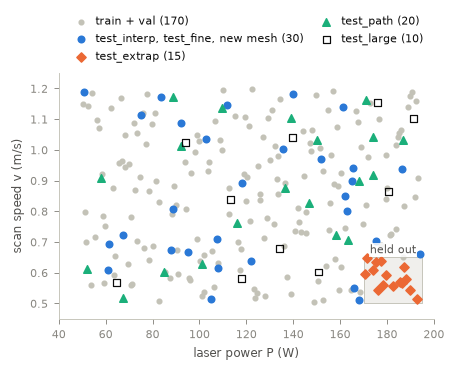

In [4]:
fig, ax = plt.subplots(figsize=(4.4, 2.9))
ax.add_patch(plt.Rectangle((170, 0.5), 25, 0.15, facecolor="#f0efec", edgecolor=AXIS, lw=0.6, zorder=0))
ax.text(182.5, 0.655, "held out", ha="center", va="bottom", color=INK2, fontsize=7, zorder=4,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.8))
groups = [(by_split["train"] + by_split["val"], "train + val", dict(s=9, color=AXIS)),
          (by_split["test_interp"], "test_interp, test_fine, new mesh", dict(s=18, color=SLOTS[0])),
          (by_split["test_extrap"], "test_extrap", dict(s=18, color=SLOTS[1], marker="D")),
          (by_split["test_path"], "test_path", dict(s=24, color=SLOTS[2], marker="^")),
          (by_split["test_large"], "test_large", dict(s=20, facecolor="none", edgecolor=INK, marker="s", lw=0.8))]
for rs, label, style in groups:
    ax.scatter([r["P"] for r in rs], [r["v"] for r in rs], label=f"{label} ({len(rs)})", zorder=3, **style)
ax.set_xlabel("laser power P (W)")
ax.set_ylabel("scan speed v (m/s)")
ax.set_xlim(40, 200)
ax.set_ylim(0.45, 1.25)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, handletextpad=0.3, columnspacing=1.0)
save(fig, "fig_splits_power_speed")
show(fig)

straight-track mesh: 5,172 nodes, 30,786 edges


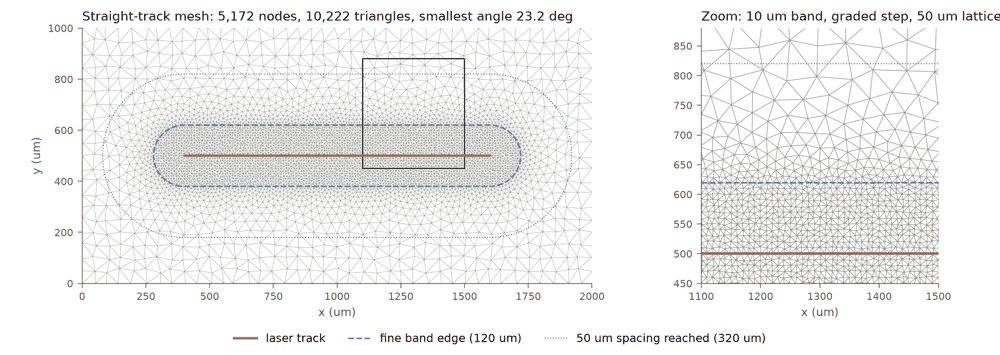

In [5]:
from graphs.figures import mesh_figure

import io
from PIL import Image as PILImage

mesh = mesh_figure(FIG_DIR / "fig_mesh_straight.png")
print(f"straight-track mesh: {mesh.n_nodes:,} nodes, {mesh.n_edges:,} edges")
preview = PILImage.open(FIG_DIR / "fig_mesh_straight.png")      # a smaller copy keeps the notebook light
preview.thumbnail((1000, 1000))
preview = preview.convert("RGB").quantize(64)
buffer = io.BytesIO()
preview.save(buffer, "PNG", optimize=True)
display(Image(data=buffer.getvalue(), width=900))

## 2. Models and training

All GNNs share one encode-process-decode backbone and training recipe; they differ only in the prediction target and the
built-in physics. Each was trained with three seeds, and the checkpoint with the lowest validation rollout error
(mean nRMSE over the 20 validation runs, checked every 2,000 steps) was kept. The settings below are read from the
stored run configurations and checkpoints.

In [6]:
from analysis.main_table import parameters

rows = []
for key, stem in GNN_STEM.items():
    cfg = yaml.safe_load(open(f"results/models/{stem}_seed0/config.yaml"))
    m, t = cfg["model"], cfg["training"]
    scores, steps = [], []
    for seed in range(3):
        ck = torch.load(f"results/models/{stem}_seed{seed}/best.pt", map_location="cpu", weights_only=False)
        scores.append(ck["score"])
        steps.append(ck["step"])
    noise_K = t.get("noise", 0) * ck["stats"]["node"]["T"]["std"]
    rows.append([LABEL[key], f"{parameters(f'results/models/{stem}_seed0/best.pt'):,}",
                 f"{m.get('width')} × {m.get('layers')}", f"{t['steps']:,}", t["batch_size"],
                 f"{t['lr']:g} → {t.get('lr_end', 0):g}", f"{t.get('noise', 0):g} σ_T ({noise_K:.0f} K)",
                 "yes" if t.get("augment") else "no",
                 t.get("precision", "fp32"), ", ".join(f"{s // 1000}k" for s in steps),
                 f"{np.mean(scores):.4f} ± {np.std(scores, ddof=1):.4f}"])
payload = torch.load(UNET_CKPT, map_location="cpu", weights_only=True)
rows.append([LABEL["unet"], f"{parameters(UNET_CKPT):,}", "3 down-sampling stages", "-", "-", "-", "-", "-", "-",
             f"epoch {payload['epoch']}", "-"])
rows.append([LABEL["lf_t"], "6", "Chebyshev order 5", "-", "-", "-", "-", "-", "-", "least squares on train", "-"])
rows.append([LABEL["fixed"], "0", "constant k, c_p", "-", "-", "-", "-", "-", "-", "nothing fitted", "-"])
md_table(["Model", "Trainable parameters", "Width × blocks", "Steps", "Batch", "Learning rate (exp. decay)",
          "Input noise", "Rotation/reflection", "Precision", "Selected at", "Val nRMSE (3 seeds)"], rows)
print("Optimiser: Adam, learning rate decayed exponentially from lr to lr_end over the run (models/train.py).\n"
      "Loss: mean squared error on the normalised one-step target (dT or dH). Input noise: Gaussian noise on the input\n"
      "temperature, as a fraction of the training spread of T, so the model learns to correct its own errors.")

| Model | Trainable parameters | Width × blocks | Steps | Batch | Learning rate (exp. decay) | Input noise | Rotation/reflection | Precision | Selected at | Val nRMSE (3 seeds) |
|---|---|---|---|---|---|---|---|---|---|---|
| GCN | 318,593 | 128 × 15 | 100,000 | 4 | 0.0003 → 1e-06 | 0.03 σ_T (11 K) | yes | bf16 | 94k, 56k, 76k | 0.0215 ± 0.0007 |
| A: MeshGraphNet | 2,331,905 | 128 × 15 | 100,000 | 4 | 0.0003 → 1e-06 | 0.03 σ_T (11 K) | yes | bf16 | 90k, 84k, 98k | 0.0036 ± 0.0002 |
| B: + linear diffusion | 2,331,905 | 128 × 15 | 100,000 | 4 | 0.0003 → 1e-06 | 0.03 σ_T (11 K) | yes | bf16 | 88k, 92k, 98k | 0.0029 ± 0.0003 |
| C: enthalpy output | 2,331,905 | 128 × 15 | 100,000 | 4 | 0.0003 → 1e-06 | 0.03 σ_T (11 K) | yes | bf16 | 82k, 90k, 98k | 0.0049 ± 0.0009 |
| D: conservative enthalpy | 2,365,058 | 128 × 15 | 100,000 | 4 | 0.0003 → 1e-06 | 0.03 σ_T (11 K) | yes | bf16 | 96k, 74k, 84k | 0.0062 ± 0.0001 |
| U-Net (grid) | 488,705 | 3 down-sampling stages | - | - | - | - | - | - | epoch 11 | - |
| LF-T (fitted filter) | 6 | Chebyshev order 5 | - | - | - | - | - | - | least squares on train | - |
| Fixed linear filter | 0 | constant k, c_p | - | - | - | - | - | - | nothing fitted | - |

Optimiser: Adam, learning rate decayed exponentially from lr to lr_end over the run (models/train.py).
Loss: mean squared error on the normalised one-step target (dT or dH). Input noise: Gaussian noise on the input
temperature, as a fraction of the training spread of T, so the model learns to correct its own errors.


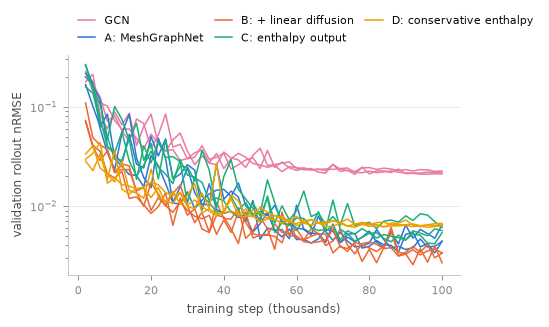

In [7]:
fig, ax = plt.subplots(figsize=(4.6, 2.6))
for key in ["gcn", "a", "b", "c", "d"]:
    for seed in range(3):
        log = list(csv.DictReader(open(f"results/models/{GNN_STEM[key]}_seed{seed}/log.csv")))
        pts = np.array([(int(r["step"]), float(r["val_score"])) for r in log if r["val_score"]])
        ax.plot(pts[:, 0] / 1000, pts[:, 1], color=COLOR[key], lw=1.0, label=LABEL[key] if seed == 0 else None)
ax.set_yscale("log")
ax.set_xlabel("training step (thousands)")
ax.set_ylabel("validation rollout nRMSE")
ax.grid(True, which="major", axis="y")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, handlelength=1.5, columnspacing=1.0)
save(fig, "fig_training_curves")
show(fig)

## 3. One closed-loop rollout per model

Every model starts from the true initial state (300 K everywhere) and then predicts the whole run from its own outputs:
75 steps of 66.7 µs, laser heating and cooling included. We use `test_path_zigzag_000`, an unseen zigzag path
(training saw only straight tracks). Each model uses its seed-0 checkpoint, and the scores are compared with the stored
evaluation files in `results/eval/`, which hold the same rollout for every run, seed and split.

The run is re-simulated here with the solver (`evaluation.rollout.simulate_like`) and interpolated onto its mesh, so
the solver's wall time is measured on this machine as well. Without the processed data set, loading a checkpoint prints
a warning that it cannot be compared with the training data; each model then uses the normalisation statistics stored
in its checkpoint, which are the ones it was trained with.

In [8]:
from evaluation.rollout import checkpoint_predictor, evaluate_run, simulate_like
from evaluation import metrics as M
from graphs.dataset import RunGraph, run_name
from graphs.preprocess import OUT as GRAPH_DIR, mesh_for_run, processed_file
from solver.ti64 import T_S

RUN = "test_path_zigzag_000"
row = next(r for r in SPLITS if run_name(r) == RUN)
t0 = time.perf_counter()
sim = simulate_like(row)
SOLVER_S = time.perf_counter() - t0
sim.update(split=row["split"], path=row["path"], name=RUN)
run = RunGraph.from_simulation(sim, mesh_for_run(sim, 0))
stored_file = processed_file(RUN, 0, GRAPH_DIR)
if os.path.exists(stored_file):
    same = RunGraph(stored_file).attrs["data_hash"] == run.attrs["data_hash"]
    print(f"processed data set file found; the fresh simulation is {'identical to it' if same else 'DIFFERENT'}")
else:
    print("processed data set not present; using the fresh simulation")
print(f"{RUN}: {row['path']} path, {row['P']:.0f} W, {row['v']:.2f} m/s; {run.last + 1} saved frames, "
      f"{run.mesh.n_nodes:,} nodes; solver wall time {SOLVER_S:.1f} s")

processed data set file found; the fresh simulation is identical to it
test_path_zigzag_000: zigzag path, 158 W, 0.72 m/s; 378 saved frames, 8,371 nodes; solver wall time 3.2 s


In [9]:
from models.linear_filter import SELECTED_CHECKPOINT, LinearFilter, LinearFilterPredictor
from models.unet_pipeline import UNet, UNetPredictor


def load_predictors(device):
    preds = {}
    for key, stem in GNN_STEM.items():
        preds[key], stride, _ = checkpoint_predictor(f"results/models/{stem}_seed0/best.pt", device)
        assert stride == 5
    # The U-Net and LF-T read the training statistics from data/graphs/ when they are loaded by their own scripts. The
    # same statistics are stored in the U-Net checkpoint, so they are taken from there and checked when possible.
    payload = torch.load(UNET_CKPT, map_location="cpu", weights_only=True)
    stats = payload["stats"]
    if os.path.exists("data/graphs/norm_stride5.json"):
        assert stats == json.load(open("data/graphs/norm_stride5.json")), "U-Net statistics differ from data/graphs"
    unet = UNet(**payload["architecture"])
    unet.load_state_dict(payload["model_state"])
    preds["unet"] = UNetPredictor(unet, stats, device)
    preds["lf_t"] = LinearFilterPredictor(json.load(open(SELECTED_CHECKPOINT)), stats, name="lf_t")
    preds["fixed"] = LinearFilter()
    return preds


class Recorder:
    # Passes every call through to a predictor and keeps its outputs, so the fields can be plotted afterwards.
    def __init__(self, inner):
        self.inner, self.name, self.frames = inner, inner.name, []

    def reset(self, run):
        self.frames = []
        if hasattr(self.inner, "reset"):
            self.inner.reset(run)

    def step(self, run, T, k, stride):
        T_next = self.inner.step(run, T, k, stride)
        self.frames.append(np.array(T_next, dtype=np.float64))
        return T_next


predictors = load_predictors(DEVICE)

results/models/gcn_seed0/best.pt: gcn gcn_seed0, step 94000, validation score 0.021488, target dT, stride 5, device cpu


results/models/model_a_seed0/best.pt: model_a model_a_seed0, step 90000, validation score 0.0036404, target dT, stride 5, device cpu


results/models/model_b_seed0/best.pt: model_b model_b_seed0, step 88000, validation score 0.0031205, target dT, stride 5, device cpu


results/models/model_c_seed0/best.pt: model_c model_c_seed0, step 82000, validation score 0.0059251, target dH, stride 5, device cpu


results/models/model_d_seed0/best.pt: model_d model_d_seed0, step 96000, validation score 0.0060864, target dH, stride 5, device cpu


In [10]:
STORED = {"gcn": "gcn_seed0", "a": "model_a_seed0", "b": "model_b_seed0", "c": "model_c_seed0", "d": "model_d_seed0",
          "unet": "unet", "lf_t": "lf_t", "fixed": "laplacian_filter"}
ROLLOUT, FIELDS = {}, {}
rows = []
for key in ["gcn", "a", "b", "c", "d", "unet", "lf_t", "fixed"]:
    rec = Recorder(predictors[key])
    r, _ = evaluate_run(run, rec, 5)
    ROLLOUT[key], FIELDS[key] = r, np.stack(rec.frames)
    stored = next(x for x in csv.DictReader(open(f"results/eval/{STORED[key]}_test_path_s5.csv")) if x["run"] == RUN)
    match = abs(r["nrmse"] - float(stored["nrmse"])) <= 1e-4 * float(stored["nrmse"])
    speed = SOLVER_S / r["wall_s"]
    rows.append([LABEL[key], f"{r['wall_s']:.2f}", f"{speed:.2f}×" if speed < 10 else f"{speed:.0f}×", f"{r['nrmse']:.4f}",
                 f"{float(stored['nrmse']):.4f}" + ("" if match else " (differs)"), f"{r['melt_mae']:.1f}",
                 f"{r['iou']:.3f}", f"{100 * r['energy_end']:+.1f}%"])
    print(f"{key:6s} done in {r['wall_s']:6.2f} s")
md_table(["Model (seed 0)", "Rollout time (s)", "Speed vs solver", "nRMSE", "Stored nRMSE", "Melting-range MAE (K)",
          "Melt-pool IoU", "Final energy error"], rows)
print(f"Solver: {SOLVER_S:.2f} s on the same machine (device for the models: {DEVICE}). "
      "Speed vs solver = solver time / rollout time.")

gcn    done in  11.17 s


a      done in  46.37 s


b      done in  48.53 s


c      done in  42.84 s


d      done in  45.47 s


unet   done in   2.75 s
lf_t   done in   0.02 s


fixed  done in   0.68 s


| Model (seed 0) | Rollout time (s) | Speed vs solver | nRMSE | Stored nRMSE | Melting-range MAE (K) | Melt-pool IoU | Final energy error |
|---|---|---|---|---|---|---|---|
| GCN | 11.17 | 0.29× | 0.2221 | 0.2221 | 350.1 | 0.296 | -27.6% |
| A: MeshGraphNet | 46.37 | 0.07× | 0.1919 | 0.1919 | 302.4 | 0.360 | -26.7% |
| B: + linear diffusion | 48.53 | 0.07× | 0.1091 | 0.1091 | 86.6 | 0.511 | +16.3% |
| C: enthalpy output | 42.84 | 0.08× | 0.1811 | 0.1811 | 278.1 | 0.397 | -24.3% |
| D: conservative enthalpy | 45.47 | 0.07× | 0.0108 | 0.0108 | 9.5 | 0.930 | -0.2% |
| U-Net (grid) | 2.75 | 1.17× | 0.1044 | 0.1044 | 81.0 | 0.760 | +14.2% |
| LF-T (fitted filter) | 0.02 | 142× | 0.3115 | 0.3115 | 243.4 | 0.447 | -37.3% |
| Fixed linear filter | 0.68 | 4.72× | 0.1510 | 0.1510 | 289.1 | 0.465 | +5.7% |

Solver: 3.23 s on the same machine (device for the models: cpu). Speed vs solver = solver time / rollout time.


The last column of the table above is the energy error at the end of the run, relative to the laser energy put in. On
this zigzag path the temperature-predicting models lose or gain heat as their errors accumulate, and their melt pools
drift away from the truth; Model D, which conserves heat exactly, stays close to the solver. The fields at the last
output frame before the laser switches off:

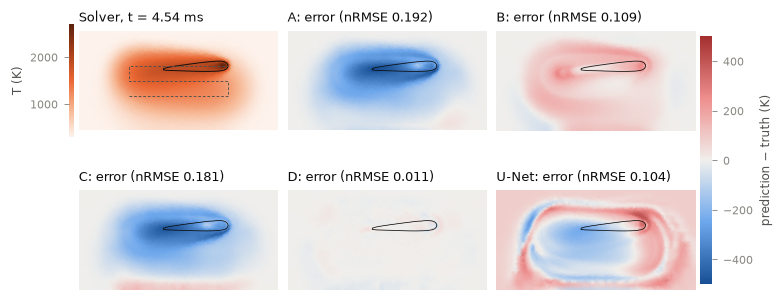

2 × 1 mm plate; dashed line: laser path; black line: true melt-pool boundary (solidus 1878 K); error colour scale clipped at ±500 K


In [11]:
frames = 5 * np.arange(1, FIELDS["a"].shape[0] + 1)
t_ms = run.t[frames] * 1e3
laser_off_ms = float(run.attrs["laser_off"]) * 1e3
j = int(np.searchsorted(t_ms, laser_off_ms, side="right") - 1)       # last output frame with the laser on
truth = run.T(frames[j])
mesh = run.mesh
tri = mtri.Triangulation(mesh.pos[:, 0] * 1e6, mesh.pos[:, 1] * 1e6, mesh.tri)
panels = ["a", "b", "c", "d", "unet"]
lim = float(np.ceil(np.percentile(np.abs(np.stack([FIELDS[k][j] - truth for k in panels])), 99.5) / 100) * 100)

fig, axes = plt.subplots(2, 3, figsize=(7.0, 2.9), layout="constrained")
ax = axes[0, 0]
im_T = ax.tripcolor(tri, truth, cmap=SEQ_HEAT, vmin=300, vmax=float(np.ceil(truth.max() / 100) * 100),
                    shading="gouraud", rasterized=True)
ax.tricontour(tri, truth, levels=[T_S], colors=INK, linewidths=0.6)
path_um = mesh.waypoints * 1e6
ax.plot(path_um[:, 0], path_um[:, 1], color=INK2, lw=0.6, ls=(0, (3, 2)))
ax.set_title(f"Solver, t = {t_ms[j]:.2f} ms")
for ax, key in zip(axes.ravel()[1:], panels):
    im_E = ax.tripcolor(tri, FIELDS[key][j] - truth, cmap=DIVERGING, vmin=-lim, vmax=lim, shading="gouraud",
                        rasterized=True)
    ax.tricontour(tri, truth, levels=[T_S], colors=INK, linewidths=0.5)
    ax.set_title(f"{SHORT[key]}: error (nRMSE {ROLLOUT[key]['nrmse']:.3f})")
for ax in axes.ravel():
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(im_T, ax=axes[0, 0], location="left", shrink=0.75, pad=0.02)
cb.set_label("T (K)")
cb.outline.set_visible(False)
cb = fig.colorbar(im_E, ax=axes[:, 2], location="right", shrink=0.8, pad=0.02)
cb.set_label("prediction − truth (K)")
cb.outline.set_visible(False)
save(fig, "fig_zigzag_fields")
show(fig)
print(f"2 × 1 mm plate; dashed line: laser path; black line: true melt-pool boundary (solidus {T_S:.0f} K); error "
      f"colour scale clipped at ±{lim:.0f} K")

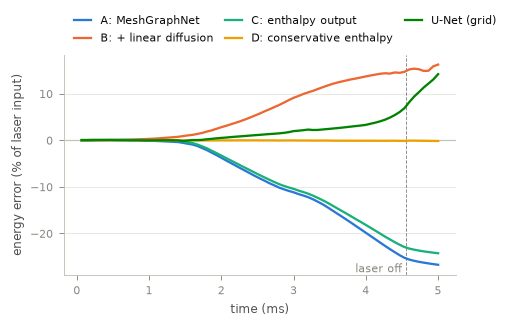

In [12]:
d = float(run.attrs["d"])
e_true = M.mesh_energy(run.T_frames(frames), run.H_from_T, run.mesh.area, d)
total_input = run.laser_input()[-1]
fig, ax = plt.subplots(figsize=(4.6, 2.6))
ax.axhline(0, color=AXIS, lw=0.8)
ax.axvline(laser_off_ms, color=MUTED, lw=0.6, ls="--")
for key in ["a", "b", "c", "d", "unet"]:
    e = M.mesh_energy(FIELDS[key], run.H_from_T, run.mesh.area, d)
    ax.plot(t_ms, 100 * (e - e_true) / total_input, color=COLOR[key], label=LABEL[key])
ax.text(laser_off_ms, ax.get_ylim()[0], "laser off ", color=MUTED, fontsize=7, ha="right", va="bottom")
ax.set_xlabel("time (ms)")
ax.set_ylabel("energy error (% of laser input)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, handlelength=1.5, columnspacing=1.0)
ax.grid(True, axis="y")
save(fig, "fig_zigzag_energy")
show(fig)

## 4. Main results: every model on every evaluation domain

`analysis/main_table.py` rebuilds the tables from the split summaries in `results/eval/` (written by
`evaluation.rollout`, `models.evaluate_unet` and `models.linear_filter_rollout`). Each metric is computed per training
seed and shown as mean ± standard deviation over the three seeds (the U-Net has one seed; the filters are deterministic).

* **nRMSE**: rollout error relative to the temperature rise, $\lVert \hat T - T\rVert / \lVert T - 300\,\mathrm{K}\rVert$
  over every node and output frame, averaged over runs.
* **Melting-range MAE**: mean absolute error (K) where the true temperature is 1,800-2,000 K.
* **IoU**: overlap of the predicted and true melt pools (melted fraction above 0.5), area-weighted.
* **Energy error**: mesh energy of the prediction minus that of the truth, relative to the laser energy put in.

In [13]:
from analysis import main_table

main_table.main()
display(Markdown(Path("results/tables/main_table.md").read_text(encoding="utf-8")))

wrote results\tables\main_table.md, main_table.csv and hypothesis.csv; reference b; missing files: 0


# Main results

Generated by `python -m analysis.main_table` from the split summaries in `results/eval/`; do not edit by hand. Closed-loop rollouts at stride 5 (66.7 us) from the true initial state. Each metric is pooled per training seed as its file pools it, then shown as mean ± sample standard deviation over seeds.

Melting-range MAE: mean absolute error where the true temperature is 1,800-2,000 K. IoU: area-weighted overlap of melted fraction above 0.5, pooled over runs, overall and per melt-pool size bin (terciles of the train split's peak pool area). Spurious pools: runs without a true pool in which the model predicts one, summed over seeds. Energy error (a): median over runs of the largest absolute energy error relative to the laser input so far, after 5% of the input. Final energy error: median signed error at the end, relative to the total laser input. Solidification durations are not reported: at stride 5 they are a diagnostic only (README, evaluation notes).

## Models

| Model | Target | Built-in physics | Parameters | Seeds |
|---|---|---|---|---|
| GCN | dT | none; ignores edge geometry | 318,593 | 3 |
| A: MeshGraphNet | dT | none | 2,331,905 | 3 |
| B: + linear diffusion | dT | fixed linear heat diffusion branch | 2,331,905 | 3 |
| C: enthalpy output | dH | exact material table T(H) | 2,331,905 | 3 |
| D: conservative enthalpy | dH (edge fluxes) | table and exact heat conservation | 2,365,058 | 3 |
| U-Net (grid) | dT | none; regular 5 um grid | 488,705 | 1 |
| LF-T (fitted linear filter) | T | linear Laplacian polynomial, fitted on train | 6 | - (deterministic) |
| Fixed linear filter | T | linear diffusion, constant k and cp, nothing fitted | 0 | - (deterministic) |
| A without augmentation (ablation) | dT | none | 2,331,905 | 3 |

## Overview: nRMSE

| Model | val | interp | new mesh | extrap | path | fine | large |
|---|---|---|---|---|---|---|---|
| GCN | 0.0215 | 0.0220 | 0.0231 | 0.0387 | 0.1296 | 0.0224 | 0.0683 |
| A: MeshGraphNet | 0.0036 | 0.0043 | 0.0118 | 0.0156 | 0.0993 | 0.0054 | 0.0114 |
| B: + linear diffusion | **0.0029** | **0.0031** | 0.0099 | **0.0045** | 0.0765 | **0.0046** | 0.0092 |
| C: enthalpy output | 0.0049 | 0.0056 | 0.0122 | 0.0168 | 0.1093 | 0.0066 | 0.0107 |
| D: conservative enthalpy | 0.0062 | 0.0065 | 0.0102 | 0.0122 | **0.0118** | 0.0072 | **0.0084** |
| U-Net (grid) | 0.0070 | 0.0074 | **0.0074** | 0.0143 | 0.0816 | 0.0075 | 0.3498 |
| LF-T (fitted linear filter) | 0.3403 | 0.3440 | 0.3449 | 0.3030 | 0.3454 | 0.3449 | 0.3468 |
| Fixed linear filter | 0.1505 | 0.1547 | 0.1547 | 0.1852 | 0.1462 | 0.1551 | 0.1508 |
| A without augmentation (ablation) | 0.0036 | 0.0043 | 0.0068 | 0.0136 | 0.1728 | 0.0056 | 0.0104 |

Bold: lowest mean, excluding the ablation.

## Overview: Melting-range MAE (K)

| Model | val | interp | new mesh | extrap | path | fine | large |
|---|---|---|---|---|---|---|---|
| GCN | 13.2 | 17.3 | 17.7 | 42.1 | 326.0 | 17.2 | 11.9 |
| A: MeshGraphNet | 4.3 | 7.1 | 8.7 | 24.1 | 252.2 | 7.9 | 4.9 |
| B: + linear diffusion | **3.7** | **3.9** | **4.7** | **4.8** | 88.5 | **5.2** | **4.6** |
| C: enthalpy output | 4.2 | 6.8 | 8.2 | 24.5 | 276.7 | 8.2 | 4.8 |
| D: conservative enthalpy | 6.3 | 6.6 | 8.6 | 9.1 | **11.5** | 7.6 | 8.8 |
| U-Net (grid) | 8.1 | 8.7 | 8.8 | 14.5 | 79.5 | 9.0 | 340.3 |
| LF-T (fitted linear filter) | 146.0 | 150.2 | 154.8 | 160.7 | 234.8 | 151.5 | 156.8 |
| Fixed linear filter | 311.3 | 305.4 | 305.2 | 296.1 | 305.1 | 305.2 | 313.2 |
| A without augmentation (ablation) | 4.3 | 6.5 | 7.6 | 19.8 | 318.9 | 7.4 | 4.7 |

Bold: lowest mean, excluding the ablation.

## Per split

### val

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.02151 ± 0.00069 | 13.2 ± 0.2 | 0.926 ± 0.006 | - | 0.903 ± 0.009 | 0.934 ± 0.005 | 0 of 27 | 2.32 ± 0.84% | -0.40 ± 0.71% |
| A: MeshGraphNet | 0.00361 ± 0.00023 | 4.3 ± 0.3 | 0.975 ± 0.002 | - | 0.960 ± 0.002 | 0.980 ± 0.002 | 0 of 27 | 1.07 ± 0.55% | 0.28 ± 0.11% |
| B: + linear diffusion | 0.00289 ± 0.00030 | 3.7 ± 0.2 | 0.977 ± 0.001 | - | 0.964 ± 0.001 | 0.982 ± 0.001 | 0 of 27 | 0.65 ± 0.34% | 0.14 ± 0.04% |
| C: enthalpy output | 0.00487 ± 0.00093 | 4.2 ± 0.3 | 0.984 ± 0.002 | - | 0.978 ± 0.002 | 0.986 ± 0.003 | 0 of 27 | 0.64 ± 0.20% | 0.01 ± 0.06% |
| D: conservative enthalpy | 0.00616 ± 0.00010 | 6.3 ± 0.4 | 0.982 ± 0.001 | - | 0.975 ± 0.003 | 0.984 ± 0.000 | 0 of 27 | 0.36 ± 0.00% | -0.20 ± 0.00% |
| U-Net (grid) | 0.00702 | 8.1 | 0.955 | - | 0.940 | 0.960 | 0 of 9 | 1.46% | -0.64% |
| LF-T (fitted linear filter) | 0.34033 | 146.0 | 0.662 | - | 0.619 | 0.683 | 2 of 9 | 39.79% | -39.79% |
| Fixed linear filter | 0.15049 | 311.3 | 0.485 | - | 0.393 | 0.568 | 3 of 9 | 10.60% | 0.13% |
| A without augmentation (ablation) | 0.00360 ± 0.00007 | 4.3 ± 0.0 | 0.975 ± 0.001 | - | 0.965 ± 0.001 | 0.979 ± 0.001 | 0 of 27 | 0.72 ± 0.46% | 0.07 ± 0.22% |

### test_interp

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.02204 ± 0.00118 | 17.3 ± 1.0 | 0.910 ± 0.007 | 0.807 ± 0.018 | 0.897 ± 0.002 | 0.917 ± 0.008 | 3 of 45 | 2.66 ± 0.83% | -0.38 ± 0.96% |
| A: MeshGraphNet | 0.00431 ± 0.00027 | 7.1 ± 0.2 | 0.961 ± 0.001 | 0.914 ± 0.011 | 0.962 ± 0.004 | 0.963 ± 0.002 | 0 of 45 | 1.38 ± 0.61% | 0.29 ± 0.12% |
| B: + linear diffusion | 0.00308 ± 0.00024 | 3.9 ± 0.3 | 0.977 ± 0.002 | 0.912 ± 0.010 | 0.955 ± 0.003 | 0.983 ± 0.002 | 0 of 45 | 0.74 ± 0.36% | 0.21 ± 0.07% |
| C: enthalpy output | 0.00561 ± 0.00108 | 6.8 ± 0.2 | 0.969 ± 0.001 | 0.965 ± 0.004 | 0.976 ± 0.002 | 0.968 ± 0.001 | 0 of 45 | 0.81 ± 0.24% | -0.03 ± 0.05% |
| D: conservative enthalpy | 0.00654 ± 0.00009 | 6.6 ± 0.3 | 0.976 ± 0.000 | 0.957 ± 0.005 | 0.970 ± 0.003 | 0.977 ± 0.001 | 0 of 45 | 0.25 ± 0.00% | -0.19 ± 0.00% |
| U-Net (grid) | 0.00740 | 8.7 | 0.953 | 0.877 | 0.928 | 0.960 | 0 of 15 | 1.56% | -0.58% |
| LF-T (fitted linear filter) | 0.34397 | 150.2 | 0.660 | 0.601 | 0.605 | 0.674 | 2 of 15 | 40.50% | -40.50% |
| Fixed linear filter | 0.15470 | 305.4 | 0.516 | 0.212 | 0.440 | 0.581 | 5 of 15 | 8.05% | -1.08% |
| A without augmentation (ablation) | 0.00433 ± 0.00015 | 6.5 ± 0.1 | 0.964 ± 0.001 | 0.913 ± 0.012 | 0.960 ± 0.005 | 0.967 ± 0.001 | 0 of 45 | 0.89 ± 0.55% | 0.07 ± 0.18% |

### test_interp, new mesh (seed 1)

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.02307 ± 0.00113 | 17.7 ± 0.9 | 0.905 ± 0.005 | 0.838 ± 0.016 | 0.892 ± 0.001 | 0.910 ± 0.005 | 3 of 45 | 2.75 ± 1.07% | -0.32 ± 0.96% |
| A: MeshGraphNet | 0.01178 ± 0.00149 | 8.7 ± 0.4 | 0.952 ± 0.002 | 0.903 ± 0.003 | 0.954 ± 0.004 | 0.954 ± 0.002 | 1 of 45 | 1.10 ± 0.15% | -0.11 ± 0.28% |
| B: + linear diffusion | 0.00990 ± 0.00230 | 4.7 ± 0.2 | 0.973 ± 0.002 | 0.904 ± 0.005 | 0.945 ± 0.004 | 0.980 ± 0.002 | 2 of 45 | 1.42 ± 0.85% | -0.23 ± 0.11% |
| C: enthalpy output | 0.01219 ± 0.00165 | 8.2 ± 0.5 | 0.962 ± 0.003 | 0.951 ± 0.002 | 0.970 ± 0.000 | 0.961 ± 0.003 | 0 of 45 | 1.44 ± 0.48% | -0.34 ± 0.31% |
| D: conservative enthalpy | 0.01023 ± 0.00011 | 8.6 ± 0.2 | 0.969 ± 0.000 | 0.935 ± 0.003 | 0.957 ± 0.004 | 0.973 ± 0.001 | 0 of 45 | 0.24 ± 0.00% | -0.20 ± 0.00% |
| U-Net (grid) | 0.00738 | 8.8 | 0.952 | 0.902 | 0.926 | 0.958 | 1 of 15 | 1.56% | -0.57% |
| LF-T (fitted linear filter) | 0.34492 | 154.8 | 0.647 | 0.586 | 0.592 | 0.662 | 2 of 15 | 40.54% | -40.54% |
| Fixed linear filter | 0.15471 | 305.2 | 0.517 | 0.210 | 0.439 | 0.583 | 5 of 15 | 8.08% | -1.09% |
| A without augmentation (ablation) | 0.00675 ± 0.00028 | 7.6 ± 0.1 | 0.959 ± 0.001 | 0.907 ± 0.009 | 0.950 ± 0.003 | 0.962 ± 0.001 | 0 of 45 | 0.95 ± 0.37% | 0.24 ± 0.29% |

### test_extrap

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.03866 ± 0.00085 | 42.1 ± 3.3 | 0.852 ± 0.009 | - | - | 0.852 ± 0.009 | 0 of 0 | 3.20 ± 0.39% | 1.21 ± 2.38% |
| A: MeshGraphNet | 0.01558 ± 0.00059 | 24.1 ± 0.7 | 0.910 ± 0.003 | - | - | 0.910 ± 0.003 | 0 of 0 | 1.32 ± 0.47% | 0.14 ± 0.17% |
| B: + linear diffusion | 0.00452 ± 0.00072 | 4.8 ± 0.4 | 0.976 ± 0.002 | - | - | 0.976 ± 0.002 | 0 of 0 | 0.52 ± 0.19% | -0.03 ± 0.12% |
| C: enthalpy output | 0.01683 ± 0.00090 | 24.5 ± 1.5 | 0.910 ± 0.004 | - | - | 0.910 ± 0.004 | 0 of 0 | 1.14 ± 0.29% | -0.18 ± 0.88% |
| D: conservative enthalpy | 0.01223 ± 0.00020 | 9.1 ± 0.1 | 0.967 ± 0.002 | - | - | 0.967 ± 0.002 | 0 of 0 | 0.36 ± 0.00% | -0.29 ± 0.00% |
| U-Net (grid) | 0.01426 | 14.5 | 0.943 | - | - | 0.943 | 0 of 0 | 1.63% | 1.37% |
| LF-T (fitted linear filter) | 0.30297 | 160.7 | 0.703 | - | - | 0.703 | 0 of 0 | 37.81% | -37.81% |
| Fixed linear filter | 0.18516 | 296.1 | 0.600 | - | - | 0.600 | 0 of 0 | 19.10% | 3.57% |
| A without augmentation (ablation) | 0.01363 ± 0.00021 | 19.8 ± 1.5 | 0.924 ± 0.003 | - | - | 0.924 ± 0.003 | 0 of 0 | 1.17 ± 0.01% | 0.10 ± 0.12% |

### test_path

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.12961 ± 0.00813 | 326.0 ± 22.1 | 0.292 ± 0.011 | 0.040 ± 0.005 | 0.237 ± 0.009 | 0.296 ± 0.011 | 0 of 18 | 12.32 ± 1.71% | -11.43 ± 1.80% |
| A: MeshGraphNet | 0.09930 ± 0.00675 | 252.2 ± 24.0 | 0.390 ± 0.030 | 0.049 ± 0.006 | 0.313 ± 0.013 | 0.395 ± 0.031 | 0 of 18 | 9.56 ± 1.22% | -8.74 ± 0.65% |
| B: + linear diffusion | 0.07648 ± 0.00809 | 88.5 ± 3.2 | 0.478 ± 0.012 | 0.145 ± 0.017 | 0.373 ± 0.025 | 0.488 ± 0.012 | 0 of 18 | 8.20 ± 0.69% | 7.74 ± 1.00% |
| C: enthalpy output | 0.10929 ± 0.00732 | 276.7 ± 42.7 | 0.371 ± 0.048 | 0.037 ± 0.010 | 0.298 ± 0.036 | 0.375 ± 0.049 | 0 of 18 | 10.32 ± 0.88% | -10.11 ± 0.94% |
| D: conservative enthalpy | 0.01185 ± 0.00014 | 11.5 ± 0.6 | 0.911 ± 0.006 | 0.338 ± 0.034 | 0.821 ± 0.008 | 0.917 ± 0.006 | 0 of 18 | 0.21 ± 0.00% | -0.14 ± 0.00% |
| U-Net (grid) | 0.08160 | 79.5 | 0.744 | 0.337 | 0.640 | 0.751 | 0 of 6 | 3.57% | 2.53% |
| LF-T (fitted linear filter) | 0.34540 | 234.8 | 0.445 | 0.499 | 0.453 | 0.444 | 0 of 6 | 39.61% | -39.61% |
| Fixed linear filter | 0.14618 | 305.1 | 0.424 | 0.094 | 0.261 | 0.442 | 2 of 6 | 9.24% | 0.97% |
| A without augmentation (ablation) | 0.17284 ± 0.00721 | 318.9 ± 6.1 | 0.302 ± 0.002 | 0.000 ± 0.000 | 0.189 ± 0.000 | 0.307 ± 0.002 | 0 of 18 | 19.27 ± 1.01% | -19.26 ± 0.99% |

### test_fine (5 um truth)

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.02236 ± 0.00125 | 17.2 ± 0.9 | 0.906 ± 0.006 | 0.796 ± 0.010 | 0.881 ± 0.010 | 0.915 ± 0.007 | 3 of 45 | 2.71 ± 0.83% | -0.41 ± 0.96% |
| A: MeshGraphNet | 0.00539 ± 0.00009 | 7.9 ± 0.2 | 0.951 ± 0.004 | 0.854 ± 0.017 | 0.928 ± 0.009 | 0.959 ± 0.003 | 0 of 45 | 1.44 ± 0.51% | 0.26 ± 0.12% |
| B: + linear diffusion | 0.00463 ± 0.00012 | 5.2 ± 0.2 | 0.967 ± 0.003 | 0.854 ± 0.005 | 0.931 ± 0.006 | 0.978 ± 0.003 | 0 of 45 | 0.80 ± 0.30% | 0.18 ± 0.06% |
| C: enthalpy output | 0.00664 ± 0.00106 | 8.2 ± 0.3 | 0.955 ± 0.003 | 0.859 ± 0.011 | 0.935 ± 0.005 | 0.962 ± 0.003 | 0 of 45 | 0.83 ± 0.29% | -0.05 ± 0.05% |
| D: conservative enthalpy | 0.00722 ± 0.00013 | 7.6 ± 0.3 | 0.967 ± 0.001 | 0.860 ± 0.017 | 0.931 ± 0.003 | 0.977 ± 0.001 | 0 of 45 | 0.22 ± 0.00% | -0.22 ± 0.00% |
| U-Net (grid) | 0.00748 | 9.0 | 0.942 | 0.811 | 0.903 | 0.953 | 0 of 15 | 1.55% | -0.62% |
| LF-T (fitted linear filter) | 0.34489 | 151.5 | 0.653 | 0.583 | 0.586 | 0.671 | 2 of 15 | 40.53% | -40.53% |
| Fixed linear filter | 0.15510 | 305.2 | 0.521 | 0.237 | 0.445 | 0.585 | 5 of 15 | 7.85% | -1.11% |
| A without augmentation (ablation) | 0.00564 ± 0.00018 | 7.4 ± 0.2 | 0.955 ± 0.003 | 0.848 ± 0.019 | 0.929 ± 0.007 | 0.963 ± 0.002 | 0 of 45 | 0.91 ± 0.59% | 0.05 ± 0.18% |
| Solver, 10 vs 5 um grid (reference gap) | 0.00507 | 4.6 | 0.976 | - | - | - | - | 0.16% | 0.00% |

### test_large

| Model | nRMSE | Melting-range MAE (K) | IoU | IoU small | IoU medium | IoU large | Spurious pools | Energy error (a) | Final energy error |
|---|---|---|---|---|---|---|---|---|---|
| GCN | 0.06828 ± 0.01244 | 11.9 ± 0.5 | 0.921 ± 0.005 | - | 0.905 ± 0.005 | 0.934 ± 0.005 | 3 of 12 | 49.14 ± 9.13% | 49.14 ± 9.13% |
| A: MeshGraphNet | 0.01141 ± 0.00054 | 4.9 ± 0.3 | 0.969 ± 0.001 | - | 0.960 ± 0.000 | 0.975 ± 0.002 | 3 of 12 | 2.42 ± 0.91% | 0.64 ± 0.39% |
| B: + linear diffusion | 0.00922 ± 0.00097 | 4.6 ± 0.1 | 0.969 ± 0.001 | - | 0.955 ± 0.001 | 0.978 ± 0.001 | 3 of 12 | 1.70 ± 0.92% | -0.40 ± 0.36% |
| C: enthalpy output | 0.01074 ± 0.00109 | 4.8 ± 0.2 | 0.979 ± 0.001 | - | 0.975 ± 0.001 | 0.981 ± 0.002 | 0 of 12 | 2.34 ± 0.35% | -0.12 ± 0.19% |
| D: conservative enthalpy | 0.00837 ± 0.00016 | 8.8 ± 0.2 | 0.971 ± 0.001 | - | 0.967 ± 0.001 | 0.974 ± 0.001 | 0 of 12 | 0.28 ± 0.00% | -0.27 ± 0.00% |
| U-Net (grid) | 0.34979 | 340.3 | 0.204 | - | 0.204 | 0.224 | 2 of 4 | 118.16% | 118.16% |
| LF-T (fitted linear filter) | 0.34678 | 156.8 | 0.601 | - | 0.601 | 0.612 | 2 of 4 | 40.72% | -40.72% |
| Fixed linear filter | 0.15083 | 313.2 | 0.470 | - | 0.441 | 0.543 | 2 of 4 | 12.16% | -1.26% |
| A without augmentation (ablation) | 0.01039 ± 0.00149 | 4.7 ± 0.0 | 0.971 ± 0.001 | - | 0.963 ± 0.003 | 0.977 ± 0.002 | 0 of 12 | 3.86 ± 0.55% | 3.82 ± 0.52% |

## Hypothesis test

Reference: the temperature-predicting GNN with the lowest val melting-range MAE, **B: + linear diffusion** (3.71 K). The proposal expects C and D to be at least 20% lower in melting-range MAE with a gain under 10% in nRMSE, which would show that the gain comes from the phase change. Changes are relative to the reference's mean; "beyond spread" means the difference exceeds the larger of the two seed standard deviations.

| Split | Model | Melting-range MAE (K) | vs reference | Beyond spread | nRMSE vs reference | Beyond spread | Expected pattern |
|---|---|---|---|---|---|---|---|
| val | C | 4.2 ± 0.3 vs 3.7 ± 0.2 | +14% | yes | +68% | yes | no |
| val | D | 6.3 ± 0.4 vs 3.7 ± 0.2 | +70% | yes | +113% | yes | no |
| interp | C | 6.8 ± 0.2 vs 3.9 ± 0.3 | +73% | yes | +82% | yes | no |
| interp | D | 6.6 ± 0.3 vs 3.9 ± 0.3 | +68% | yes | +113% | yes | no |
| new mesh | C | 8.2 ± 0.5 vs 4.7 ± 0.2 | +74% | yes | +23% | no | no |
| new mesh | D | 8.6 ± 0.2 vs 4.7 ± 0.2 | +83% | yes | +3% | no | no |
| extrap | C | 24.5 ± 1.5 vs 4.8 ± 0.4 | +408% | yes | +272% | yes | no |
| extrap | D | 9.1 ± 0.1 vs 4.8 ± 0.4 | +89% | yes | +170% | yes | no |
| path | C | 276.7 ± 42.7 vs 88.5 ± 3.2 | +213% | yes | +43% | yes | no |
| path | D | 11.5 ± 0.6 vs 88.5 ± 3.2 | -87% | yes | -85% | yes | melting target met, but overall gain is larger |
| fine | C | 8.2 ± 0.3 vs 5.2 ± 0.2 | +58% | yes | +43% | yes | no |
| fine | D | 7.6 ± 0.3 vs 5.2 ± 0.2 | +46% | yes | +56% | yes | no |
| large | C | 4.8 ± 0.2 vs 4.6 ± 0.1 | +4% | no | +16% | yes | no |
| large | D | 8.8 ± 0.2 vs 4.6 ± 0.1 | +92% | yes | -9% | no | no |

The melting-range target is met in 1 of 14 model and split pairs: D on path.


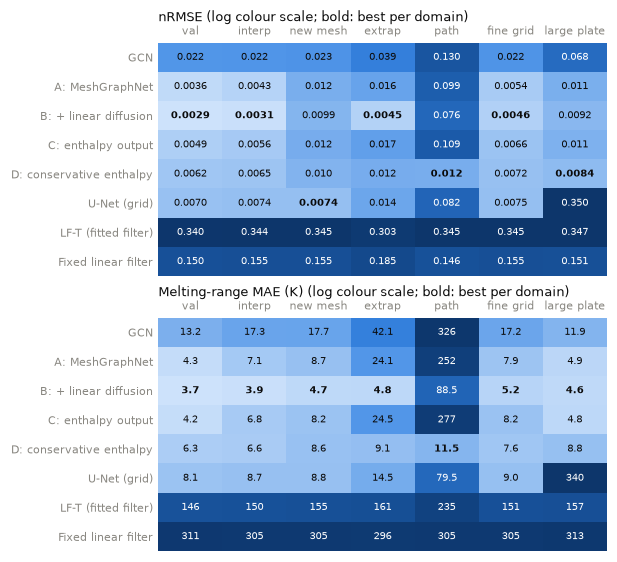

In [14]:
TABLE = {}
for r in csv.DictReader(open("results/tables/main_table.csv")):
    TABLE[r["model"], r["split"], r["metric"]] = (float(r["mean"]) if r["mean"] else np.nan,
                                                   float(r["std"]) if r["std"] else np.nan)
DOMAINS = [d for d, _ in main_table.DOMAINS]
DOMAIN_LABEL = {"val": "val", "test_interp": "interp", "test_interp_seed1": "new mesh", "test_extrap": "extrap",
                "test_path": "path", "test_fine": "fine grid", "test_large": "large plate"}
HEAT_ROWS = ["gcn", "a", "b", "c", "d", "unet", "lf_t", "fixed"]

fig, axes = plt.subplots(2, 1, figsize=(5.5, 5.0), layout="constrained")
for ax, metric, title in [(axes[0], "nrmse", "nRMSE"), (axes[1], "melt_mae", "Melting-range MAE (K)")]:
    V = np.array([[TABLE[k, dmn, metric][0] for dmn in DOMAINS] for k in HEAT_ROWS])
    norm = LogNorm(vmin=np.nanmin(V), vmax=np.nanmax(V))
    im = ax.imshow(V, cmap=SEQ_BLUE, norm=norm, aspect="auto")
    best = np.nanargmin(V, axis=0)
    for i in range(V.shape[0]):
        for jj in range(V.shape[1]):
            v = V[i, jj]
            if metric == "nrmse":
                text = f"{v:.3f}" if v >= 0.01 else f"{v:.4f}"
            else:
                text = f"{v:.1f}" if v < 100 else f"{v:.0f}"
            dark = norm(v) > 0.55
            ax.text(jj, i, text, ha="center", va="center", fontsize=6.8, color="white" if dark else INK,
                    fontweight="bold" if best[jj] == i else "normal")
    ax.set_xticks(range(len(DOMAINS)), [DOMAIN_LABEL[dmn] for dmn in DOMAINS])
    ax.set_yticks(range(len(HEAT_ROWS)), [LABEL[k] for k in HEAT_ROWS])
    ax.tick_params(length=0)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title + " (log colour scale; bold: best per domain)", pad=14)
save(fig, "fig_main_heatmap")
show(fig)

## 5. Hypothesis test

The proposal's hypothesis: predicting enthalpy (C, D) cuts the melting-range error by at least 20 % relative to the
best temperature-predicting GNN, with a gain under 10 % in overall nRMSE, which would show that the gain comes from the
phase change. The reference is the temperature-predicting GNN with the lowest **validation** melting-range MAE, chosen
before looking at the test splits.

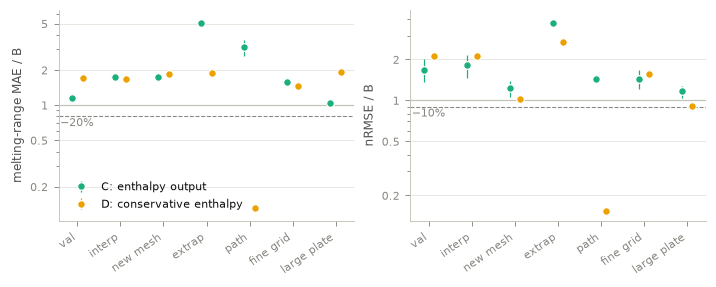

reference: B: + linear diffusion (val melting-range MAE 3.71 K)
melting-range target (≥ 20% lower) met in 1 of 14 model/split pairs: D on path: melt -87%, nRMSE -85%


In [15]:
hyp = list(csv.DictReader(open("results/tables/hypothesis.csv")))
reference = hyp[0]["reference"]
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5), sharex=True, layout="constrained")
x = np.arange(len(DOMAINS))
for ax, metric, ref_line, ylabel in [(axes[0], "melt_mae", 0.8, f"melting-range MAE / {SHORT[reference]}"),
                                     (axes[1], "nrmse", 0.9, f"nRMSE / {SHORT[reference]}")]:
    ax.axhline(1, color=AXIS, lw=0.8)
    ax.axhline(ref_line, color=MUTED, lw=0.7, ls="--")
    ax.text(-0.4, ref_line * 0.97, f"−{100 * (1 - ref_line):.0f}%", color=MUTED, fontsize=7, va="top", ha="left")
    for off, key in [(-0.12, "c"), (0.12, "d")]:
        ratio = [TABLE[key, dmn, metric][0] / TABLE[reference, dmn, metric][0] for dmn in DOMAINS]
        err = [TABLE[key, dmn, metric][1] / TABLE[reference, dmn, metric][0] for dmn in DOMAINS]
        ax.errorbar(x + off, ratio, yerr=err, fmt="o", ms=5, color=COLOR[key], mec="white", mew=0.8, elinewidth=0.8,
                    label=LABEL[key])
    ax.set_yscale("log")
    plain_log_ticks(ax, [0.1, 0.2, 0.5, 1, 2, 5])
    ax.set_ylabel(ylabel)
    ax.set_xticks(x, [DOMAIN_LABEL[dmn] for dmn in DOMAINS], rotation=35, ha="right")
    ax.grid(True, axis="y", which="major")
axes[0].legend(loc="lower left", ncol=1)
save(fig, "fig_hypothesis")
show(fig)

met = [h for h in hyp if h["melt_target_met"] == "True"]
print(f"reference: {LABEL[reference]} (val melting-range MAE {TABLE[reference, 'val', 'melt_mae'][0]:.2f} K)")
print(f"melting-range target (≥ 20% lower) met in {len(met)} of {len(hyp)} model/split pairs: "
      + "; ".join(f"{SHORT[h['model']]} on {DOMAIN_LABEL[h['split']]}: melt {100 * float(h['melt_change']):+.0f}%, "
                  f"nRMSE {100 * float(h['nrmse_change']):+.0f}%" for h in met))

## 6. Ablation: rotation and reflection augmentation (Model A)

All final GNNs are trained with random rotations and reflections of each training sample (the physics is isotropic and
the plate edges are insulated). Model A was also trained without it, three seeds each; the change on each domain:

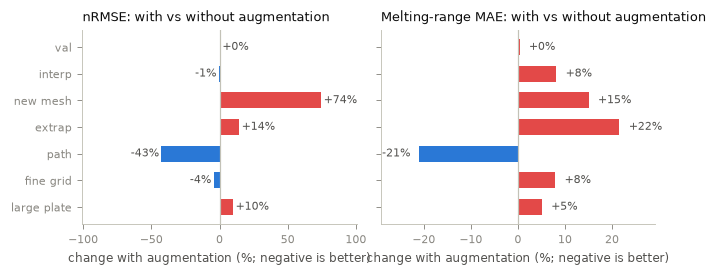

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(6.0, 2.4), sharey=True, layout="constrained")
y = np.arange(len(DOMAINS))[::-1]
for ax, metric, title in [(axes[0], "nrmse", "nRMSE"), (axes[1], "melt_mae", "Melting-range MAE")]:
    change = np.array([100 * (TABLE["a", dmn, metric][0] / TABLE["a_noaug", dmn, metric][0] - 1) for dmn in DOMAINS])
    colors = [SLOTS[0] if c < 0 else SLOTS[7] for c in change]
    ax.barh(y, change, height=0.6, color=colors)
    ax.axvline(0, color=AXIS, lw=0.8)
    for yy, c in zip(y, change):
        ax.text(c + (2 if c >= 0 else -2), yy, f"{c:+.0f}%", va="center", ha="left" if c >= 0 else "right",
                fontsize=7, color=INK2)
    ax.set_title(f"{title}: with vs without augmentation")
    ax.set_xlabel("change with augmentation (%; negative is better)")
    span = np.abs(change).max() * 1.35
    ax.set_xlim(-span, span)
axes[0].set_yticks(y, [DOMAIN_LABEL[dmn] for dmn in DOMAINS])
save(fig, "fig_ablation_augmentation")
show(fig)

## 7. Summary

The numbers below are read from the tables rebuilt above.

In [17]:
T = lambda k, dmn, m="nrmse": TABLE[k, dmn, m][0]
best_on = {dmn: min(HEAT_ROWS, key=lambda k: T(k, dmn)) for dmn in DOMAINS}
b_best = [DOMAIN_LABEL[dmn] for dmn in DOMAINS if best_on[dmn] == "b"]
c_better = sum(float(h["melt_change"]) < 0 for h in hyp if h["model"] == "c")
lines = [
    f"* **Exact heat conservation generalises to unseen paths.** On test_path, D scores nRMSE {T('d', 'test_path'):.4f} "
    f"against {T('a', 'test_path'):.3f} (A), {T('b', 'test_path'):.3f} (B) and {T('c', 'test_path'):.3f} (C); its "
    f"melting-range MAE is {T('d', 'test_path', 'melt_mae'):.1f} K and its melt-pool IoU "
    f"{T('d', 'test_path', 'iou'):.2f} (best other GNN: {max(T(k, 'test_path', 'iou') for k in ['gcn', 'a', 'b', 'c']):.2f}).",
    f"* **The linear diffusion branch helps on straight tracks.** B has the lowest nRMSE on {len(b_best)} of "
    f"{len(DOMAINS)} domains ({', '.join(b_best)}). It also extrapolates to the held-out high-energy corner far better "
    f"than A (melting-range MAE {T('b', 'test_extrap', 'melt_mae'):.1f} K vs {T('a', 'test_extrap', 'melt_mae'):.1f} K).",
    f"* **The hypothesis is not supported.** The melting-range target is met in {len(met)} of {len(hyp)} model and split "
    "pairs" + (": " + "; ".join(f"{SHORT[h['model']]} on {DOMAIN_LABEL[h['split']]}, where nRMSE falls by "
                                 f"{-100 * float(h['nrmse_change']):.0f}% as well, so the gain is not specific to the "
                                 "melting range" for h in met) if met else "") + ". The enthalpy target alone (C) "
    + (f"never lowers the melting-range MAE below {SHORT[reference]}'s." if c_better == 0 else
       f"lowers the melting-range MAE below {SHORT[reference]}'s on {c_better} of {len(DOMAINS)} domains."),
    f"* **Augmentation is a trade-off for A:** nRMSE {100 * (T('a', 'test_path') / T('a_noaug', 'test_path') - 1):+.0f}% "
    f"on unseen paths, {100 * (T('a', 'test_interp_seed1') / T('a_noaug', 'test_interp_seed1') - 1):+.0f}% on the new "
    f"mesh, {100 * (T('a', 'test_extrap') / T('a_noaug', 'test_extrap') - 1):+.0f}% on extrapolation.",
    f"* **The grid U-Net** is best on the new mesh ({T('unet', 'test_interp_seed1'):.4f}) but fails on the large plate "
    f"(nRMSE {T('unet', 'test_large'):.3f}); both linear filters are far behind every learned model.",
]
fastest = max(SOLVER_S / ROLLOUT[k]["wall_s"] for k in GNN_STEM)
lines.append(
    f"* **Speed:** on this machine ({DEVICE}) the solver needs {SOLVER_S:.1f} s for the zigzag run and the GNN rollouts "
    f"{min(ROLLOUT[k]['wall_s'] for k in GNN_STEM):.1f}-{max(ROLLOUT[k]['wall_s'] for k in GNN_STEM):.1f} s, so "
    + ("every GNN is slower than the solver here." if fastest < 1 else f"the fastest GNN is {fastest:.1f}× faster.")
    + " For this 2D problem the surrogates bring at most a modest speed-up; the study is about built-in physics.")
display(Markdown("\n".join(lines)))

* **Exact heat conservation generalises to unseen paths.** On test_path, D scores nRMSE 0.0118 against 0.099 (A), 0.076 (B) and 0.109 (C); its melting-range MAE is 11.5 K and its melt-pool IoU 0.91 (best other GNN: 0.48).
* **The linear diffusion branch helps on straight tracks.** B has the lowest nRMSE on 4 of 7 domains (val, interp, extrap, fine grid). It also extrapolates to the held-out high-energy corner far better than A (melting-range MAE 4.8 K vs 24.1 K).
* **The hypothesis is not supported.** The melting-range target is met in 1 of 14 model and split pairs: D on path, where nRMSE falls by 85% as well, so the gain is not specific to the melting range. The enthalpy target alone (C) never lowers the melting-range MAE below B's.
* **Augmentation is a trade-off for A:** nRMSE -43% on unseen paths, +74% on the new mesh, +14% on extrapolation.
* **The grid U-Net** is best on the new mesh (0.0074) but fails on the large plate (nRMSE 0.350); both linear filters are far behind every learned model.
* **Speed:** on this machine (cpu) the solver needs 3.2 s for the zigzag run and the GNN rollouts 11.2-48.5 s, so every GNN is slower than the solver here. For this 2D problem the surrogates bring at most a modest speed-up; the study is about built-in physics.

## Reproducing the evaluation files

The files in `results/eval/` come from the commands below (one per model, seed and domain; about 20-35 s each on a GPU).
They need the processed data set: `python -m data.generate` and `python -m graphs.preprocess` (see the README).

```bash
python -m evaluation.rollout --split test_path --checkpoint results/models/model_d_seed0/best.pt --device cuda
python -m evaluation.rollout --split test_interp --mesh-seed 1 --checkpoint results/models/model_d_seed0/best.pt
python -m models.evaluate_unet --checkpoint checkpoints/unet_early_stop_retry_group_s5_seed0.pt --split val
python -m models.linear_filter_rollout --split test_interp
python -m evaluation.rollout --split val --predictor laplacian
python -m analysis.main_table
```